# Which temperature should the LLM score with?

**Temperature** sets how much randomness the model uses when it writes its answer. At 0 it always gives the same
score for the same text. Above 0 the score can change from one try to the next, so each call was scored
**5 times** and the scores were averaged (`--samples 5`).

**Setup**
- **Calls:** the dev set (`data/processed/dev300.csv`): 300 random in-sample calls from the early half of Q4 2025
  (event dates 2025-10-01 to 2025-11-05). The later calls are the hold-out and are not used here.
- **Model:** `qwen3:30b-a3b-instruct-2507-q4_K_M`, scoring the summaries (the same setup as the full run).
- **Runs:** temperature 0 (the base run, one score per call) and 0.3, 0.7 and 1.0 (5 scores per call, averaged).
- **Measure:** day-0 R², as in `llm_eval`: how much of the ranking of the event-day abnormal return the score
  explains. Higher is better.

**Answer: keep temperature 0.**
- **No temperature does better.** The R² is 3.91% at 0, 3.85% at 0.3, 3.90% at 0.7 and 3.62% at 1.0. Every
  difference is within ±0.3 percentage points, much smaller than the noise on 300 calls.
- **One sample at a higher temperature is worse** (2.8% to 3.6%). Averaging 5 samples only brings it back to about
  what temperature 0 gives in a single try.
- **Temperature 0 is 4 times cheaper**: 1 second per call against 4.2 seconds for 5 samples.
- **The one gain from higher temperatures is finer scores**: 49 distinct values at 1.0 against 11 at 0. But the
  largest group of tied calls only shrinks from 24% to 19% of calls, so ties still need a tie-break rule.

The numbers in this text are from the run of 2026-11-14; the cells below recompute them from the files.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from llm_based_earnings_surprise_ntam.llm.llm_common import (DEV_IDS, MERGED, MODEL, SCORES, load_all, read_ids,
                                                             with_run_defaults)

pd.set_option('display.width', 200)

# Same chart style as the other notebooks; categorical colors in fixed order
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})
pct1 = mtick.PercentFormatter(1, decimals=1)
pct0 = mtick.PercentFormatter(1, decimals=0)
pp = mtick.FuncFormatter(lambda v, _: f'{v * 100:+.1f} pp')

## 1. Load the dev-set scores

The scores come from `llm_scores.parquet` plus the GPU jobs' shard files, so the notebook works before and after
`llm_combine`. Each run is one temperature with a fixed number of samples per call.

In [2]:
RUNS = {0.0: 1, 0.3: 5, 0.7: 5, 1.0: 5}   # temperature -> scores per call
TEMPS = list(RUNS)
LABELS = [f'{t:.1f}' if t else '0' for t in TEMPS]   # 0, 0.3, 0.7, 1.0
NAME = dict(zip(TEMPS, LABELS))

dev = read_ids(DEV_IDS)
calls = pd.read_parquet(MERGED, columns=['transcriptid', 'in_sample', 'event_date', 'r_abn_pct', 'sue_pct_sample'])
calls['transcriptid'] = calls.transcriptid.astype('int64')
calls = calls[calls.in_sample.fillna(False).astype(bool) & calls.transcriptid.isin(dev)].set_index('transcriptid')

s = with_run_defaults(load_all(SCORES))
s['transcriptid'] = s.transcriptid.astype('int64')
s = s[s.transcriptid.isin(dev) & s.model.eq(MODEL) & s.source.eq('summary') & s.variant.eq('base')
      & s.temperature.map(RUNS).eq(s.samples)]
s = s.drop_duplicates(['transcriptid', 'temperature', 'samples'], keep='last')

avg = s.pivot(index='transcriptid', columns='temperature', values='prediction')   # the average of the samples
m = calls.join(avg, how='inner')
assert len(m) == len(calls) and m[TEMPS].notna().all().all(), 'some dev calls have no score for a temperature'

# every single sample, one row per call: shape (calls, samples)
draws = {t: np.array([json.loads(p) for p in g.set_index('transcriptid').loc[m.index, 'predictions']], dtype=float)
         for t, g in s[s.temperature > 0].groupby('temperature')}
draws[0.0] = m[[0.0]].to_numpy()
seconds = s.groupby('temperature').seconds.median()
y, sue = m.r_abn_pct.to_numpy(), m.sue_pct_sample.to_numpy()

print(f'{len(m)} dev calls, event dates {m.event_date.min():%Y-%m-%d} to {m.event_date.max():%Y-%m-%d}')
print(s.groupby(['temperature', 'samples']).size().rename('calls scored').to_frame())

300 dev calls, event dates 2025-10-01 to 2025-11-05
                     calls scored
temperature samples              
0.0         1                 300
0.3         5                 300
0.7         5                 300
1.0         5                 300


## 2. Compare the temperatures

For each temperature: the R² of the score alone and on top of the surprise, the change against temperature 0, and
how fine-grained and stable the scores are.

The **95% intervals** come from a bootstrap: the 300 calls are resampled 2,000 times and the R² recomputed each
time. Every temperature uses the same resamples, so the change against temperature 0 compares the same calls
(a paired comparison, which is more precise than comparing two separate intervals).

In [3]:
def r2(y, *xs):
    # R² of an OLS regression of y on a constant and xs (as in llm_eval)
    X = np.column_stack([np.ones(len(y)), *xs])
    resid = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    return 1 - resid.var() / y.var()

idx = np.random.default_rng(0).integers(0, len(m), size=(2000, len(m)))   # same resamples for every temperature
def boot(stat):
    # the statistic on all calls, and on each resample
    return stat(np.arange(len(m))), np.array([stat(i) for i in idx])

x0 = m[0.0].to_numpy()
r2_sue = r2(y, sue)
res = []
for t in TEMPS:
    x = m[t].to_numpy()
    alone, alone_b = boot(lambda i: r2(y[i], x[i]))
    change, change_b = boot(lambda i: r2(y[i], x[i]) - r2(y[i], x0[i]))
    counts = m[t].value_counts()
    res.append({'temperature': t, 'samples': RUNS[t], 'alone': alone,
                'alone_lo': np.percentile(alone_b, 2.5), 'alone_hi': np.percentile(alone_b, 97.5),
                'added': r2(y, x, sue) - r2_sue,
                'change': change, 'change_lo': np.percentile(change_b, 2.5), 'change_hi': np.percentile(change_b, 97.5),
                'better_share': (change_b > 0).mean() if t else np.nan,
                'one_sample': r2(y, draws[t][:, 0]),
                'distinct': m[t].nunique(), 'tie_share': counts.iloc[0] / len(m),
                'spread': np.nanstd(draws[t], axis=1, ddof=1).mean() if RUNS[t] > 1 else 0.0,
                'corr_t0': np.corrcoef(x, x0)[0, 1], 'seconds': seconds[t]})
res = pd.DataFrame(res).set_index('temperature')

table = pd.DataFrame({
    'scores per call': res.samples.astype(str),
    'R² of the LLM score alone': res.alone.map('{:.2%}'.format),
    '   95% interval': [f'{lo:.1%} to {hi:.1%}' for lo, hi in zip(res.alone_lo, res.alone_hi)],
    'R² added on top of the surprise': res.added.map('{:.2%}'.format),
    'change vs temperature 0': res.change.map(lambda v: f'{v * 100:+.2f} pp'),
    '   95% interval ': [f'{lo * 100:+.2f} to {hi * 100:+.2f} pp' for lo, hi in zip(res.change_lo, res.change_hi)],
    '   share of resamples where better': res.better_share.map(lambda v: '-' if np.isnan(v) else f'{v:.0%}'),
    'R² from one sample only': res.one_sample.map('{:.2%}'.format),
    'distinct score values': res.distinct.astype(str),
    'largest group of tied calls': res.tie_share.map('{:.0%}'.format),
    'spread across the 5 samples (SD)': res.spread.map('{:.3f}'.format),
    'correlation with temperature 0': res.corr_t0.map('{:.3f}'.format),
    'seconds per call (median)': res.seconds.map('{:.1f}'.format),
}).T
table.columns = [f'temperature {NAME[t]}' for t in res.index]
print(f'Surprise alone (same 300 calls): R² {r2_sue:.2%}')
table

Surprise alone (same 300 calls): R² 4.22%


,temperature 0,temperature 0.3,temperature 0.7,temperature 1.0
scores per call,1,5,5,5
R² of the LLM score alone,3.91%,3.85%,3.90%,3.62%
95% interval,0.6% to 9.5%,0.6% to 9.5%,0.6% to 9.4%,0.4% to 9.0%
R² added on top of the surprise,2.68%,2.55%,2.59%,2.38%
change vs temperature 0,+0.00 pp,-0.07 pp,-0.01 pp,-0.29 pp
95% interval,+0.00 to +0.00 pp,-0.54 to +0.43 pp,-0.52 to +0.53 pp,-0.94 to +0.32 pp
share of resamples where better,-,35%,46%,17%
R² from one sample only,3.91%,3.42%,3.64%,2.82%
distinct score values,11,29,39,49
largest group of tied calls,24%,23%,20%,19%


**Reading the table**
- **R² alone** barely moves, and the change against temperature 0 is within a fraction of a percentage point with
  an interval that includes zero. Only in 17% to 46% of resamples does a higher temperature beat temperature 0: a
  coin flip or worse.
- **One sample only:** a single score at a higher temperature explains less than the temperature-0 score. The
  randomness adds noise, and averaging 5 samples only removes it again.
- **Correlation with temperature 0** is 0.99: the averaged scores are almost the same scores, just with more
  decimals.

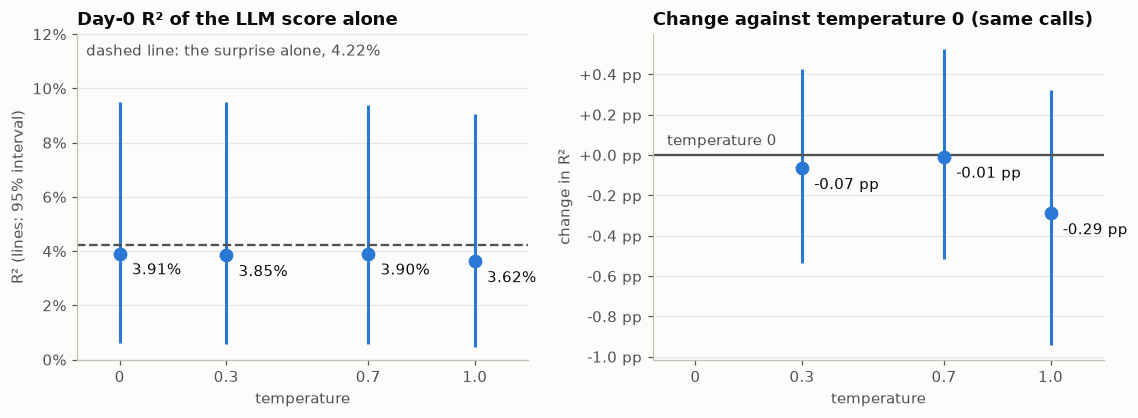

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9))

a1.errorbar(TEMPS, res.alone, yerr=[res.alone - res.alone_lo, res.alone_hi - res.alone],
            fmt='o', color=BLUE, ms=8, elinewidth=2, capsize=0)
for t, v in res.alone.items():
    a1.annotate(f'{v:.2%}', (t, v), xytext=(8, -6), textcoords='offset points', va='top', color=INK)
a1.axhline(r2_sue, color=INK2, ls='--', lw=1.5)
a1.text(0.02, 0.97, f'dashed line: the surprise alone, {r2_sue:.2%}', transform=a1.transAxes, va='top',
        color=INK2)
a1.set_title('Day-0 R² of the LLM score alone')
a1.set_ylabel('R² (lines: 95% interval)')
a1.yaxis.set_major_formatter(pct0)
a1.set_ylim(0, 0.12)

later = res.loc[res.index > 0]
a2.errorbar(later.index, later.change, yerr=[later.change - later.change_lo, later.change_hi - later.change],
            fmt='o', color=BLUE, ms=8, elinewidth=2, capsize=0)
for t, v in later.change.items():
    a2.annotate(f'{v * 100:+.2f} pp', (t, v), xytext=(8, -6), textcoords='offset points', va='top', color=INK)
a2.axhline(0, color=INK2, lw=1.5)
a2.annotate('temperature 0', (-0.08, 0), xytext=(0, 4), textcoords='offset points', ha='left', va='bottom',
            color=INK2)
a2.set_title('Change against temperature 0 (same calls)')
a2.set_ylabel('change in R²')
a2.yaxis.set_major_formatter(pp)

for a in (a1, a2):
    a.set_xticks(TEMPS, LABELS)
    a.set_xlim(-0.12, 1.15)
    a.set_xlabel('temperature')
    a.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

## 3. Does averaging more samples help?

At each higher temperature, the R² of the average of the first 1, 2, ..., 5 samples. If randomness helped, the
lines would climb above the temperature-0 line. They only climb back up to it.

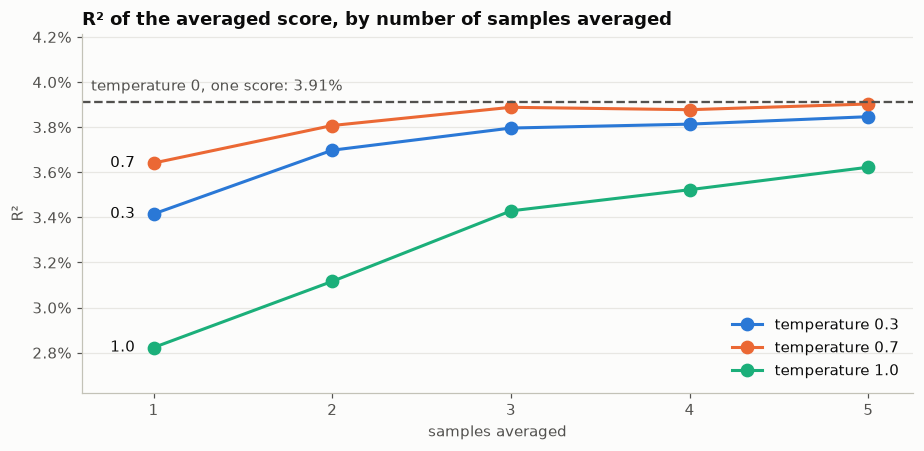

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
k = np.arange(1, 6)
for t, color in zip([0.3, 0.7, 1.0], [BLUE, ORANGE, AQUA]):
    curve = [r2(y, draws[t][:, :n].mean(axis=1)) for n in k]
    ax.plot(k, curve, color=color, marker='o', ms=8, label=f'temperature {NAME[t]}')
    ax.annotate(NAME[t], (1, curve[0]), xytext=(-12, 0), textcoords='offset points', ha='right', va='center',
                color=INK)
ax.axhline(res.loc[0.0, 'alone'], color=INK2, ls='--', lw=1.5)
ax.annotate(f'temperature 0, one score: {res.loc[0.0, "alone"]:.2%}', (0.65, res.loc[0.0, 'alone']),
            xytext=(0, 5), textcoords='offset points', ha='left', va='bottom', color=INK2)
lo = min(min(l.get_ydata()) for l in ax.get_lines() if len(l.get_ydata()) > 2)
ax.set_ylim(lo - 0.002, res.loc[0.0, 'alone'] + 0.003)
ax.set_title('R² of the averaged score, by number of samples averaged')
ax.set_xlabel('samples averaged')
ax.set_ylabel('R²')
ax.set_xticks(k)
ax.set_xlim(0.6, 5.25)
ax.yaxis.set_major_formatter(pct1)
ax.grid(axis='x', visible=False)
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

## 4. Finer scores, but ties remain

The model mostly answers with round numbers (0.6, 0.65, 0.7, ...). Averaging samples at a higher temperature gives
more distinct values, which matters when the calls are sorted into fifths for the backtest. But a large group of
calls still shares one score at every temperature.

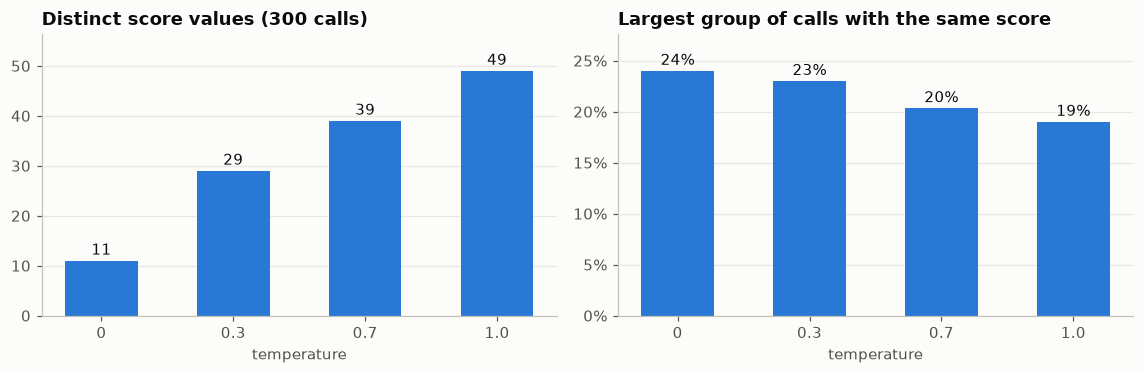

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.5))
pos = np.arange(len(TEMPS))
a1.bar(pos, res.distinct, color=BLUE, width=0.55)
for i, v in enumerate(res.distinct):
    a1.annotate(f'{v}', (i, v), xytext=(0, 4), textcoords='offset points', ha='center', color=INK)
a1.set_title(f'Distinct score values ({len(m)} calls)')
a2.bar(pos, res.tie_share, color=BLUE, width=0.55)
for i, v in enumerate(res.tie_share):
    a2.annotate(f'{v:.0%}', (i, v), xytext=(0, 4), textcoords='offset points', ha='center', color=INK)
a2.set_title('Largest group of calls with the same score')
a2.yaxis.set_major_formatter(pct0)
for a in (a1, a2):
    a.set_xticks(pos, LABELS)
    a.set_xlabel('temperature')
    a.grid(axis='x', visible=False)
    a.margins(y=0.15)
fig.tight_layout()
plt.show()

## 5. Conclusion

**Keep temperature 0** for the hold-out test and the backtest (it is already the base run that `llm_merge` uses).

- **Same predictive power:** no temperature beats 0, and the differences are far inside the noise of 300 calls.
- **Cheaper and simpler:** one deterministic score per call, about 1 second, and a rerun gives the same answer.
- **Higher temperatures only add noise:** one sample is worse, and averaging 5 just brings it back to where
  temperature 0 already is.

**Ties.** The only real gain from averaging is finer scores, and it does not remove the tie problem (19% to 24% of
calls share one score). Handle ties with an explicit rule in the backtest instead, for example break them by the
earnings surprise, or average the ranks of tied calls.

**Limits.** 300 calls from one quarter: the R² intervals run from about 0.5% to 9.5%, so this test can rule out
large gains from temperature, not small ones. Temperature was only tested on scoring, not on the summaries.